# 08 — Pandas : analyser des mesures de capteurs

Un capteur d'ambiance a enregistré la température, l'humidité, la tension
d'alimentation et le courant absorbé toutes les 10 secondes pendant 5 heures.
Avant d'entraîner un modèle d'intelligence artificielle sur de telles
mesures, il faut savoir les charger, les filtrer, les résumer et vérifier
leur qualité. C'est exactement le rôle de **Pandas**.

**Objectifs du notebook**

- charger un fichier CSV avec des dates et inspecter sa structure ;
- sélectionner, renommer et créer des colonnes ;
- filtrer les mesures anormales (pointes de courant) ;
- calculer des statistiques robustes et des seuils d'alarme ;
- rééchantillonner une série temporelle et la lisser ;
- contrôler la qualité des données avant tout apprentissage.

**Prérequis** : variables, listes, dictionnaires, boucles, fonctions et
tableaux NumPy (notebooks 01 à 06). Aucune connaissance de Pandas n'est
supposée.


## Utilisation en ligne (Google Colab)

Cette cellule ne fait rien sur votre ordinateur. Dans Google Colab, elle
clone le dépôt public (données comprises) et place le notebook à sa racine,
afin que les chemins `data/...` fonctionnent. Exécutez-la en premier.


In [1]:
import os  # manipulation des chemins et du dossier courant
import subprocess  # lance la commande git clone
import sys  # permet de détecter l'environnement Colab

DEPOT = "https://github.com/VladdKid/python-electronique-ia.git"  # adresse publique du cours
DOSSIER = "python-electronique-ia"  # dossier local créé par le clone

if "google.colab" in sys.modules and not os.path.isdir("data"):  # uniquement dans Colab, si les données manquent
    if not os.path.isdir(DOSSIER):  # évite de cloner deux fois le dépôt
        subprocess.run(["git", "clone", "--depth", "1", DEPOT, DOSSIER], check=True)  # télécharge le cours
    os.chdir(DOSSIER)  # se place à la racine du dépôt cloné
    print(f"Dépôt prêt : {os.getcwd()}")  # confirme le dossier de travail


## 1. Charger et inspecter un fichier CSV

`pd.read_csv` lit un fichier texte dont la première ligne contient les noms
de colonnes. L'option `parse_dates` convertit la colonne `horodatage` en
vraies dates : indispensable pour les calculs temporels. Le chemin est
relatif à la racine du dépôt, d'où `data/...`.


In [2]:
import pandas as pd  # importe pandas : tableaux de données et séries temporelles
import numpy as np  # importe numpy : calculs numériques (moyenne, écart-type)
import matplotlib.pyplot as plt  # importe matplotlib pour tracer des courbes

mesures = pd.read_csv("data/mesures_capteur.csv", parse_dates=["horodatage"])  # lit le CSV et convertit horodatage en dates
mesures.head()  # affiche les 5 premières lignes du tableau


,horodatage,temperature_C,humidite_pct,tension_V,courant_mA
0,2026-09-14 08:00:00,21.44,48.9,5.028,12.06
1,2026-09-14 08:00:10,21.55,48.3,5.023,12.04
2,2026-09-14 08:00:20,21.60,47.2,5.025,12.12
3,2026-09-14 08:00:30,21.37,47.6,5.025,12.14
4,2026-09-14 08:00:40,21.64,46.7,5.024,12.10


`tail` montre la fin de l'enregistrement, `shape` donne les dimensions et
`dtypes` le type de chaque colonne. Un capteur qui enregistre toutes les
10 s pendant 5 h produit 1800 lignes : on vérifie ici que le fichier est
complet.


In [3]:
mesures.tail()  # affiche les 5 dernières lignes : fin de l'enregistrement
print(mesures.shape)  # dimensions : 1800 lignes de mesures et 5 colonnes


(1800, 5)


`info` complète `shape` : il donne le type de chaque colonne et confirme
qu'aucune valeur ne manque. Sur un capteur, un `float64` là où l'on attend
une date signale immédiatement un problème de format.


In [4]:
mesures.info()  # résumé : nombre de lignes, colonnes, types et mémoire utilisée
mesures.dtypes  # type de chaque colonne : dates et nombres décimaux (float64)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1800 entries, 0 to 1799
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   horodatage     1800 non-null   datetime64[ns]
 1   temperature_C  1800 non-null   float64       
 2   humidite_pct   1800 non-null   float64       
 3   tension_V      1800 non-null   float64       
 4   courant_mA     1800 non-null   float64       
dtypes: datetime64[ns](1), float64(4)
memory usage: 70.4 KB


horodatage       datetime64[ns]
temperature_C           float64
humidite_pct            float64
tension_V               float64
courant_mA              float64
dtype: object

`describe` calcule d'un coup le nombre de valeurs, la moyenne, l'écart-type,
le minimum, les quartiles et le maximum. C'est le premier réflexe à avoir
devant un jeu de mesures : il révèle immédiatement une plage de valeurs
incohérente (tension négative, humidité à 300 %...).


In [5]:
mesures.describe().round(2)  # statistiques descriptives arrondies à 2 décimales


,horodatage,temperature_C,humidite_pct,tension_V,courant_mA
count,1800,1800.00,1800.00,1800.00,1800.00
mean,2026-09-14 10:29:54.999999744,21.50,51.18,5.02,12.13
min,2026-09-14 08:00:00,19.28,46.10,5.00,10.75
25%,2026-09-14 09:14:57.500000,20.24,49.80,5.01,11.38
50%,2026-09-14 10:29:55,21.49,51.40,5.02,12.00
75%,2026-09-14 11:44:52.500000,22.78,52.50,5.03,12.61
max,2026-09-14 12:59:50,23.74,55.60,5.04,58.32
std,NaN,1.29,1.75,0.01,2.37


## 2. Sélectionner, renommer et calculer des colonnes

On accède à une colonne avec `mesures["nom"]` et à plusieurs colonnes avec
une liste de noms. `rename` change un nom sans toucher aux données. Enfin,
le calcul vectorisé `tension × courant` crée une colonne **puissance** :
des volts multipliés par des milliampères donnent directement des milliwatts.


In [6]:
mesures = mesures.rename(columns={"humidite_pct": "humidite_relative_pct"})  # renomme la colonne d'humidité en nom plus explicite
colonnes_utiles = ["horodatage", "tension_V", "courant_mA"]  # liste des colonnes qui nous intéressent
mesures[colonnes_utiles].head(3)  # sélectionne ces trois colonnes et affiche 3 lignes
mesures["puissance_mW"] = mesures["tension_V"] * mesures["courant_mA"]  # P = U × I : volts × milliampères = milliwatts
mesures[["horodatage", "puissance_mW"]].head(3)  # vérifie la nouvelle colonne calculée


,horodatage,puissance_mW
0,2026-09-14 08:00:00,60.63768
1,2026-09-14 08:00:10,60.47692
2,2026-09-14 08:00:20,60.90300


## 3. Filtrer les pointes de courant

Un filtre s'écrit `mesures[condition]` : la condition est évaluée ligne par
ligne et renvoie un booléen. Ici, on isole les mesures où le courant dépasse
20 mA, alors que le fonctionnement normal se situe autour de 12 mA.
`.loc` permet de filtrer **et** de choisir la colonne en une seule opération.


In [7]:
pointes = mesures[mesures["courant_mA"] > 20.0]  # garde uniquement les lignes dont le courant dépasse 20 mA
print(f"Pointes détectées : {len(pointes)}")  # affiche le nombre de pointes (6 sur 1800 mesures)
pointes[["horodatage", "courant_mA"]]  # affiche la date et la valeur de chaque pointe


Pointes détectées : 6


,horodatage,courant_mA
662,2026-09-14 09:50:20,51.17
835,2026-09-14 10:19:10,47.49
908,2026-09-14 10:31:20,49.09
1317,2026-09-14 11:39:30,45.22
1377,2026-09-14 11:49:30,58.32
1412,2026-09-14 11:55:20,56.57


La table des pointes est courte, mais un diagnostic a souvent besoin de la
liste des dates pour la recouper avec un journal d'événements. `.loc` répond
à ce besoin en une seule ligne, sans créer de tableau intermédiaire.


In [8]:
dates_pointes = mesures.loc[mesures["courant_mA"] > 20.0, "horodatage"]  # .loc : lignes filtrées et colonne choisie
print(dates_pointes.to_list())  # affiche la liste des 6 horodatages de pointe
mesures.nlargest(3, "courant_mA")[["horodatage", "courant_mA"]]  # les 3 mesures de plus fort courant


[Timestamp('2026-09-14 09:50:20'), Timestamp('2026-09-14 10:19:10'), Timestamp('2026-09-14 10:31:20'), Timestamp('2026-09-14 11:39:30'), Timestamp('2026-09-14 11:49:30'), Timestamp('2026-09-14 11:55:20')]


,horodatage,courant_mA
1377,2026-09-14 11:49:30,58.32
1412,2026-09-14 11:55:20,56.57
662,2026-09-14 09:50:20,51.17


`sort_values` trie le tableau selon une colonne. Trier par courant décroissant
et garder les premières lignes est une autre façon de trouver les valeurs
extrêmes, utile quand on veut aussi voir les colonnes voisines (tension,
température) au moment de la pointe.


In [9]:
mesures_triees = mesures.sort_values("courant_mA", ascending=False)  # trie par courant décroissant
mesures_triees[["horodatage", "courant_mA", "tension_V"]].head(3)  # les 3 plus fortes valeurs et leur contexte


,horodatage,courant_mA,tension_V
1377,2026-09-14 11:49:30,58.32,5.017
1412,2026-09-14 11:55:20,56.57,5.022
662,2026-09-14 09:50:20,51.17,5.012


## 4. Statistiques : moyenne, médiane et seuils

La **moyenne** additionne toutes les valeurs : six pointes à 50 mA suffisent
à la décaler. La **médiane** est la valeur qui coupe l'échantillon en deux :
elle ignore l'amplitude des extrêmes. Comparer les deux est le moyen le plus
simple de repérer des valeurs aberrantes dans une série de mesures.


In [10]:
moyenne = mesures["courant_mA"].mean()  # moyenne arithmétique, tirée vers le haut par les pointes
mediane = mesures["courant_mA"].median()  # médiane : 50 % des mesures sont en dessous
ecart_type = mesures["courant_mA"].std()  # écart-type : dispersion autour de la moyenne
print(f"Moyenne : {moyenne:.2f} mA | Médiane : {mediane:.2f} mA | Écart-type : {ecart_type:.2f} mA")  # affiche les trois indicateurs


Moyenne : 12.13 mA | Médiane : 12.00 mA | Écart-type : 2.37 mA


Moyenne et médiane résument le centre, mais pas les extrêmes. `min`, `max`
et `idxmax` localisent la mesure la plus critique et l'instant où elle a eu
lieu : c'est le point de départ d'un diagnostic de capteur.


In [11]:
minimum = mesures["courant_mA"].min()  # plus petite valeur mesurée
maximum = mesures["courant_mA"].max()  # plus grande valeur mesurée
position_max = mesures["courant_mA"].idxmax()  # étiquette de la ligne qui contient le maximum
print(f"Minimum : {minimum:.2f} mA | Maximum : {maximum:.2f} mA (ligne {position_max})")  # affiche les extrêmes


Minimum : 10.75 mA | Maximum : 58.32 mA (ligne 1377)


Le quantile à 0,95 vaut environ 12,9 mA : 95 % des mesures sont en dessous.
Il décrit donc la **plage normale**, pas les défauts. Comme les pointes ne
représentent que 0,3 % des points, aucun quantile « raisonnable » ne les
isole : un seuil d'alarme se choisit avec la connaissance du capteur, ici
20 mA, soit bien au-dessus du bruit de mesure.


In [12]:
seuil_95 = mesures["courant_mA"].quantile(0.95)  # 95 % des mesures sont sous ce seuil : plage normale
seuil_alerte = 20.0  # seuil d'alarme fixé au-dessus de la variabilité normale
nb_alertes = (mesures["courant_mA"] > seuil_alerte).sum()  # compte les mesures dépassant le seuil d'alarme
print(f"Seuil 95 % : {seuil_95:.2f} mA | Alarme : {seuil_alerte:.0f} mA | Alertes : {nb_alertes}")  # affiche les seuils et le compte


Seuil 95 % : 12.92 mA | Alarme : 20 mA | Alertes : 6


## 5. Série temporelle : rééchantillonnage et lissage

En mettant l'horodatage en **index**, Pandas sait que les lignes sont
ordonnées dans le temps. `resample("5min")` regroupe alors les mesures par
tranche de 5 minutes (30 échantillons) et `.mean()` calcule la moyenne de
chaque tranche : le volume de données baisse sans perdre la tendance.


In [13]:
serie = mesures.set_index("horodatage")["courant_mA"]  # indexe les mesures par la date et ne garde que le courant
print(serie.index.is_monotonic_increasing)  # True : les dates sont classées par ordre croissant
moyenne_5min = serie.resample("5min").mean()  # moyenne par tranche de 5 minutes
print(moyenne_5min.shape)  # 60 tranches de 5 min pour 5 heures d'enregistrement
moyenne_5min.head(3)  # aperçu des 3 premières tranches


True
(60,)


horodatage
2026-09-14 08:00:00    12.027333
2026-09-14 08:05:00    12.135000
2026-09-14 08:10:00    12.255000
Freq: 5min, Name: courant_mA, dtype: float64

La moyenne **glissante** `rolling(window=30)` calcule la moyenne des 30
dernières mesures à chaque instant, soit 5 minutes. Contrairement au
rééchantillonnage, elle conserve 1800 points. Les 29 premiers résultats sont
`NaN` car la fenêtre n'est pas encore remplie.


In [14]:
serie_lissee = serie.rolling(window=30).mean()  # moyenne glissante sur 30 échantillons = 5 minutes
print(f"Valeurs NaN au début : {serie_lissee.isna().sum()}")  # 29 valeurs NaN : la fenêtre n'est pas encore pleine
print(f"Maximum lissé : {serie_lissee.max():.2f} mA")  # une pointe isolée est fortement atténuée par le lissage
serie_lissee.iloc[28:33]  # affiche la transition entre NaN et premières valeurs calculées


Valeurs NaN au début : 29
Maximum lissé : 13.97 mA


horodatage
2026-09-14 08:04:40          NaN
2026-09-14 08:04:50    12.027333
2026-09-14 08:05:00    12.025333
2026-09-14 08:05:10    12.029333
2026-09-14 08:05:20    12.033333
Name: courant_mA, dtype: float64

Regrouper par heure résume la dérive lente du capteur : la température suit
l'échauffement de la pièce, tandis que le courant moyen reste stable. C'est
ce type de variable agrégée que l'on donnera plus tard à un modèle.


In [15]:
temperature_horaire = mesures.set_index("horodatage")["temperature_C"].resample("1h").mean()  # température moyenne par heure
print(temperature_horaire.round(2))  # affiche les 5 valeurs horaires (8 h à 12 h)


horodatage
2026-09-14 08:00:00    22.50
2026-09-14 09:00:00    23.11
2026-09-14 10:00:00    21.48
2026-09-14 11:00:00    19.91
2026-09-14 12:00:00    20.50
Freq: h, Name: temperature_C, dtype: float64


## 6. Contrôle de qualité des données

Avant d'entraîner un modèle, on vérifie trois choses : pas de valeurs
manquantes, pas d'horodatage en double, et un ordre chronologique correct.
Une valeur manquante fait planter scikit-learn ; un doublon double le poids
d'une mesure ; un désordre temporel fausse les moyennes glissantes et la
validation croisée des séries temporelles.


In [16]:
nan_par_colonne = mesures.isna().sum()  # compte les valeurs manquantes colonne par colonne
print(f"Valeurs manquantes : {nan_par_colonne.sum()}")  # 0 : le fichier est complet
doublons = mesures["horodatage"].duplicated().sum()  # nombre d'horodatages présents plusieurs fois
print(f"Horodatages en double : {doublons}")  # 0 : un seul enregistrement par instant


Valeurs manquantes : 0
Horodatages en double : 0


## 7. Visualiser le courant et le seuil d'alarme

Une figure vaut mieux qu'un tableau de 1800 lignes : on superpose le courant
brut, sa moyenne glissante et le seuil d'alarme. Les six pointes doivent
apparaître comme des traits verticaux isolés, et la courbe lissée doit rester
autour de 12 mA.


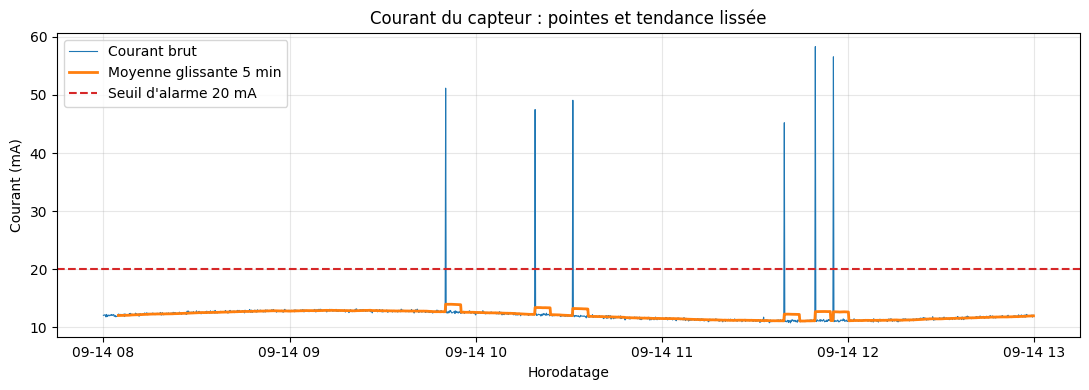

In [17]:
fig, ax = plt.subplots(figsize=(11, 4))  # crée une figure de 11 × 4 pouces
ax.plot(mesures["horodatage"], mesures["courant_mA"], color="tab:blue", lw=0.8, label="Courant brut")  # trace les 1800 mesures
ax.plot(serie_lissee.index, serie_lissee, color="tab:orange", lw=2, label="Moyenne glissante 5 min")  # superpose la tendance lissée
ax.axhline(seuil_alerte, color="tab:red", ls="--", label="Seuil d'alarme 20 mA")  # ligne horizontale du seuil d'alarme
ax.set_title("Courant du capteur : pointes et tendance lissée")  # titre du graphique
ax.set_xlabel("Horodatage")  # légende de l'axe horizontal
ax.set_ylabel("Courant (mA)")  # légende de l'axe vertical
ax.legend(loc="upper left")  # affiche la légende en haut à gauche
ax.grid(alpha=0.3)  # ajoute une grille discrète
plt.tight_layout()  # ajuste les marges pour éviter les chevauchements
plt.show()  # affiche la figure dans le notebook


## 8. À vous de jouer

Complétez les cellules suivantes. Les commentaires indiquent la marche à
suivre ; utilisez les mêmes méthodes que dans le notebook.


**Exercice 1** — Combien de mesures dépassent 40 mA ? Affichez leur date et
leur courant, puis vérifiez que ce nombre est cohérent avec les 6 pointes
détectées plus haut.


In [18]:
# TODO : créez un filtre mesures["courant_mA"] > 40.0

# TODO : affichez le nombre de lignes obtenu avec len(...)

# TODO : affichez les colonnes horodatage et courant_mA de ces lignes


**Exercice 2** — Calculez le temps écoulé entre deux pointes consécutives.
La méthode `.diff()` appliquée à la série des horodatages donne directement
les écarts ; affichez-les en minutes.


In [19]:
# TODO : triez les horodatages des pointes par ordre croissant (sort_values)

# TODO : calculez les écarts avec .diff() puis convertissez-les en minutes

# TODO : affichez les écarts obtenus et commentez s'ils sont réguliers


**Exercice 3** — Calculez la température moyenne pour chaque heure de la
journée avec `dt.hour` et `groupby`, puis affichez l'heure la plus chaude.
Indice : `.idxmax()` sur la série des moyennes donne cette heure.


In [20]:
# TODO : créez une colonne heure avec mesures["horodatage"].dt.hour

# TODO : calculez la température moyenne par heure avec groupby

# TODO : affichez la série et l'heure de température maximale


## 9. À retenir

- `pd.read_csv(..., parse_dates=[...])` charge un CSV en respectant les dates.
- `head`, `shape`, `info`, `describe` donnent une première vue du jeu de données.
- `df[condition]` filtre, `.loc[condition, "colonne"]` filtre et sélectionne,
  `nlargest` et `sort_values` isolent les extrêmes.
- La médiane est robuste aux pointes, la moyenne ne l'est pas : comparez-les.
- `set_index` + `resample` agrègent le temps, `rolling` lisse sans réduire
  le nombre de points.
- Un contrôle de qualité (NaN, doublons, ordre) précède tout entraînement.

**Notebook suivant** : `09 — Traitement du signal`, où nous filtrerons un
signal bruité et l'analyserons avec la transformée de Fourier. Le notebook
`10 — Apprentissage automatique` réutilisera directement ces mesures.
